**Student:** Tonny Kibanda (2160579)
**Topic:** Data profiling (functional dependency discovery)

# Reproducing HyFD (Papenbrock & Naumann, 2016)

**Paper:** T. Papenbrock and F. Naumann (2016). *A Hybrid Approach to Functional Dependency Discovery.* SIGMOD 2016.

**Main experiment reproduced: Table 1 (Section 10.4).** The paper runs HyFD and seven other functional dependency (FD) discovery algorithms on many real-world datasets and reports, per dataset, the number of minimal FDs and the runtime of every algorithm. The claim is that HyFD finds the same FDs and is usually the fastest.

**Implementation.** The authors' code is written in Java for the Metanome framework. Here we use the Python library **Desbordante**, which contains all eight algorithms of Table 1: TANE, FUN, FD_Mine, DFD, Dep-Miner, FastFDs, Fdep and HyFD. This keeps the comparison fair, because all algorithms run in the same library, like in the paper.

**Extra experiment:** row scalability (in the style of Figure 6) on the Adult dataset.

Files needed in the same folder: this notebook and `run_algo.py`.

### How to run this notebook
1. Put `reproduce_hyfd.ipynb` and `run_algo.py` in the same folder. In Google Colab, upload `run_algo.py` via the Files panel on the left.
2. Run the first code cell: it installs the required libraries (`desbordante`, `numpy`, `pandas`, `matplotlib`).
3. Choose **Run all**. The datasets are downloaded automatically from the UCI repository.

**Note:** a full run takes 2–3 hours, because some algorithms are very slow on the larger datasets. For a quick check, set `TIME_LIMIT = 60` and `REPEATS = 1` in the parameters cell. All results from my own run are already saved in this notebook, so it does not need to be rerun.

## 1. Setup

In [2]:
# Run once if needed:
!pip install desbordante numpy pandas matplotlib

import csv, json, os, subprocess, sys, urllib.request, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.0/7.0 MB 22.7 MB/s eta 0:00:00


### Parameters
All parameters are set in this cell so they can be reported in one place.

In [33]:
DATA_DIR = "data"
TIME_LIMIT = 600        # seconds per algorithm run (paper: 4 hours = 14,400 s)
THREADS = 1             # single-threaded, as in Table 1 of the paper
REPEATS = 3             # runs per algorithm and dataset, median is reported
MAX_LHS = None          # no limit on left-hand side size (Guardian not used)
NULL_SEMANTICS = "null = null"   # as in the paper (Section 10.1): missing values
                                 # ('?' or empty) are compared as ordinary values
ALGORITHMS = ["Tane", "Fun", "FdMine", "Dfd", "DepMiner", "FastFDs", "Fdep", "HyFD"]
SCALING_ROWS = [1000, 2000, 4000, 8000, 16000, 32000, 48842]  # extra experiment

## 2. Datasets

The paper's Table 1 datasets that are publicly available on the UCI Machine Learning Repository are downloaded automatically. If a download fails, download the file by hand from the URL and put it in `data/`.

Not included: **ncvoter** (1,000-row extract made by the authors), **fd-reduced-30** (synthetic, generated by the authors), **plista**, **flight** and **uniprot** (not in the UCI repository).

Preparation:
* Every value is read as text, without a header.
* Rows of different lengths (a few in echocardiogram) are padded with empty values to the most common length.
* **Adult** = `adult.data` + `adult.test` (48,842 rows). In `adult.test` the class label ends with a full stop (`>50K.`); this is kept, as in the original files.
* **Horse** = `horse-colic.data` + `horse-colic.test` (368 rows); the file is separated by spaces.

In [34]:
UCI = "https://archive.ics.uci.edu/ml/machine-learning-databases/"
DOWNLOAD_TIMEOUT = 30   # seconds per download attempt
MIRROR = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/"

def download(file, urls):
    os.makedirs(DATA_DIR, exist_ok=True)
    path = os.path.join(DATA_DIR, file)
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return path
    for url in urls:
        try:
            with urllib.request.urlopen(url, timeout=DOWNLOAD_TIMEOUT) as r, open(path, "wb") as f:
                f.write(r.read())
            return path
        except Exception as e:
            print(f"  could not download {url} ({e})")
    if os.path.exists(path):
        os.remove(path)
    return None

def read(path, sep=",", skip_first=False):
    with open(path, newline="") as f:
        if sep == " ":
            rows = [line.split() for line in f]
        else:
            rows = [[v.strip() for v in r] for r in csv.reader(f, delimiter=sep)]
    rows = [r for r in rows if r and any(v != "" for v in r)]
    if skip_first:
        rows = rows[1:]
    width = pd.Series([len(r) for r in rows]).mode()[0]
    rows = [(r + [""] * width)[:width] for r in rows]
    return pd.DataFrame(rows, dtype=str)

def uci(file, folder_file, sep=",", mirror=None):
    urls = [UCI + folder_file] + ([MIRROR + mirror] if mirror else [])
    path = download(file, urls)
    return read(path, sep) if path else None

def load_adult():
    train = download("adult.data", [UCI + "adult/adult.data"])
    test = download("adult.test", [UCI + "adult/adult.test"])
    if train and test:
        return pd.concat([read(train), read(test, skip_first=True)], ignore_index=True)
    path = download("adult-all.csv", [MIRROR + "adult-all.csv"])
    if not path:
        return None
    df = read(path)             # mirror removed the full stops: put them back
    df.iloc[32561:, -1] = df.iloc[32561:, -1] + "."
    return df

def load_horse():
    a = download("horse-colic.data", [UCI + "horse-colic/horse-colic.data"])
    b = download("horse-colic.test", [UCI + "horse-colic/horse-colic.test"])
    if not (a and b):
        return None
    return pd.concat([read(a, " "), read(b, " ")], ignore_index=True)

DATASETS = {
    "iris": uci("iris.data", "iris/iris.data", mirror="iris.csv"),
    "balance-scale": uci("balance-scale.data", "balance-scale/balance-scale.data"),
    "chess": uci("krkopt.data", "chess/king-rook-vs-king/krkopt.data"),
    "abalone": uci("abalone.data", "abalone/abalone.data", mirror="abalone.csv"),
    "nursery": uci("nursery.data", "nursery/nursery.data"),
    "breast-cancer": uci("breast-cancer-wisconsin.data",
                         "breast-cancer-wisconsin/breast-cancer-wisconsin.data",
                         mirror="breast-cancer-wisconsin.data"),
    "bridges": uci("bridges.data.version1", "bridges/bridges.data.version1"),
    "echocardiogram": uci("echocardiogram.data", "echocardiogram/echocardiogram.data"),
    "adult": load_adult(),
    "letter": uci("letter-recognition.data", "letter-recognition/letter-recognition.data"),
    "hepatitis": uci("hepatitis.data", "hepatitis/hepatitis.data"),
    "horse": load_horse(),
}

# write each dataset as a clean CSV for the algorithm runs
for name, df in DATASETS.items():
    if df is not None:
        df.to_csv(os.path.join(DATA_DIR, f"{name}.prepared.csv"), header=False, index=False)
    print(f"{name:15s}", "MISSING" if df is None else f"{len(df):>6} rows x {df.shape[1]:>2} columns")

iris               150 rows x  5 columns
balance-scale      625 rows x  5 columns
chess            28056 rows x  7 columns
abalone           4177 rows x  9 columns
nursery          12960 rows x  9 columns
breast-cancer      699 rows x 11 columns
bridges            108 rows x 13 columns
echocardiogram     132 rows x 13 columns
adult            48842 rows x 15 columns
letter           20000 rows x 17 columns
hepatitis          155 rows x 20 columns
horse              368 rows x 28 columns


## 3. Values reported in the paper (Table 1)
Runtimes in seconds. `TL` = time limit of 4 hours exceeded, `ML` = memory limit of 100 GB exceeded.

In [35]:
PAPER = pd.DataFrame([
    # dataset,        cols, rows,  FDs,   Tane, Fun,  FdMine, Dfd,  DepMiner, FastFDs, Fdep,  HyFD
    ("iris",            5,   150,     4,    1.1,  0.1,   0.2,   0.2,    0.2,    0.2,    0.1,  0.1),
    ("balance-scale",   5,   625,     1,    1.2,  0.1,   0.2,   0.3,    0.3,    0.3,    0.2,  0.1),
    ("chess",           7, 28056,     1,    2.9,  1.1,   3.8,   1.0,  174.6,  164.2,  125.5,  0.2),
    ("abalone",         9,  4177,   137,    2.1,  0.6,   1.8,   1.1,    3.0,    2.9,    3.8,  0.2),
    ("nursery",         9, 12960,     1,    4.1,  1.8,   7.1,   0.9,  121.2,  118.9,   46.8,  0.5),
    ("breast-cancer",  11,   699,    46,    2.3,  0.6,   2.2,   0.8,    1.1,    1.1,    0.5,  0.2),
    ("bridges",        13,   108,   142,    2.2,  0.6,   4.2,   0.9,    0.5,    0.6,    0.2,  0.1),
    ("echocardiogram", 13,   132,   527,    1.6,  0.4,  69.9,   1.2,    0.5,    0.5,    0.2,  0.1),
    ("adult",          14, 48842,    78,   67.4, 111.6, 531.5,  5.9, 6039.2, 6033.8,  860.2,  1.1),
    ("letter",         17, 20000,    61,  260.0, 529.0, 7204.8, 6.0, 1090.0, 1015.5,  291.3,  3.4),
    ("hepatitis",      20,   155,  8250,   12.2, 175.9,  "ML", 326.7, 5576.5,   9.5,    0.8,  0.6),
    ("horse",          27,   368, 128727, 457.0, "TL",  "ML",  "TL",   "TL",  385.8,    7.2,  7.1),
], columns=["dataset", "cols", "rows", "FDs"] + ALGORITHMS).set_index("dataset")
PAPER

,cols,rows,FDs,Tane,Fun,FdMine,Dfd,DepMiner,FastFDs,Fdep,HyFD
dataset,,,,,,,,,,,
iris,5,150,4,1.1,0.1,0.2,0.2,0.2,0.2,0.1,0.1
balance-scale,5,625,1,1.2,0.1,0.2,0.3,0.3,0.3,0.2,0.1
chess,7,28056,1,2.9,1.1,3.8,1.0,174.6,164.2,125.5,0.2
abalone,9,4177,137,2.1,0.6,1.8,1.1,3.0,2.9,3.8,0.2
nursery,9,12960,1,4.1,1.8,7.1,0.9,121.2,118.9,46.8,0.5
breast-cancer,11,699,46,2.3,0.6,2.2,0.8,1.1,1.1,0.5,0.2
bridges,13,108,142,2.2,0.6,4.2,0.9,0.5,0.6,0.2,0.1
echocardiogram,13,132,527,1.6,0.4,69.9,1.2,0.5,0.5,0.2,0.1
adult,14,48842,78,67.4,111.6,531.5,5.9,6039.2,6033.8,860.2,1.1


## 4. Running the algorithms

Each algorithm runs in a separate process (`run_algo.py`), so a run that exceeds `TIME_LIMIT` can be stopped and marked `TL`, as in the paper. Only the discovery itself is timed, not reading the file. The reported runtime is the median of `REPEATS` runs.

In [36]:
def run(algorithm, csv_path, repeats=REPEATS):
    """Return (number of FDs, median seconds) or ('TL'/'error', None)."""
    times, fds = [], None
    for _ in range(repeats):
        try:
            out = subprocess.run([sys.executable, "run_algo.py", algorithm, csv_path, str(THREADS)],
                                 capture_output=True, text=True, timeout=TIME_LIMIT)
        except subprocess.TimeoutExpired:
            return "TL", None
        if out.returncode != 0:
            print(f"    {algorithm} failed: {out.stderr.strip()[-300:]}")
            return "error", None
        r = json.loads(out.stdout.strip().splitlines()[-1])
        fds = r["fds"]
        times.append(r["seconds"])
        if r["seconds"] > 60:      # long runs: one repeat is enough
            break
    return fds, float(np.median(times))

## 5. Experiment: Table 1

In [37]:
fd_counts, runtimes = {}, {}
for name, df in DATASETS.items():
    if df is None:
        continue
    path = os.path.join(DATA_DIR, f"{name}.prepared.csv")
    fd_counts[name], runtimes[name] = {}, {}
    for algo in ALGORITHMS:
        n, t = run(algo, path)
        fd_counts[name][algo] = n
        runtimes[name][algo] = round(t, 3) if t is not None else n   # "TL" or "error"
        print(f"{name:15s} {algo:9s} FDs={n!s:>7}  time={runtimes[name][algo]}")

fd_counts = pd.DataFrame(fd_counts).T
runtimes = pd.DataFrame(runtimes).T

iris            Tane      FDs=      4  time=0.0
iris            Fun       FDs=      4  time=0.001
iris            FdMine    FDs=      4  time=0.001
iris            Dfd       FDs=      4  time=0.001
iris            DepMiner  FDs=      4  time=0.001
iris            FastFDs   FDs=      4  time=0.001
iris            Fdep      FDs=      4  time=0.001
iris            HyFD      FDs=      4  time=0.0
balance-scale   Tane      FDs=      1  time=0.001
balance-scale   Fun       FDs=      1  time=0.002
balance-scale   FdMine    FDs=      1  time=0.002
balance-scale   Dfd       FDs=      1  time=0.001
balance-scale   DepMiner  FDs=      1  time=0.032
balance-scale   FastFDs   FDs=      1  time=0.032
balance-scale   Fdep      FDs=      1  time=0.014
balance-scale   HyFD      FDs=      1  time=0.001
chess           Tane      FDs=      1  time=0.145
chess           Fun       FDs=      1  time=0.249
chess           FdMine    FDs=      1  time=0.286
chess           Dfd       FDs=      1  time=0.114
ches

KeyboardInterrupt: 

**Note:** the Table 1 run above was stopped manually (hence the KeyboardInterrupt) because Dep-Miner, FastFDs and Fdep on adult take 860–6,000+ seconds in the paper. The cell below runs HyFD on adult, marks the unfinished runs as "stopped", and builds the result tables. The letter, hepatitis and horse datasets were therefore not run.

In [38]:
# Finish the interrupted dataset: run HyFD (fast), mark the other missing runs as stopped
for name in list(runtimes):
    for algo in ALGORITHMS:
        if algo not in runtimes[name]:
            if algo == "HyFD":
                path = os.path.join(DATA_DIR, f"{name}.prepared.csv")
                n, t = run(algo, path)
                fd_counts[name][algo] = n
                runtimes[name][algo] = round(t, 3) if t is not None else n
            else:
                fd_counts[name][algo] = "stopped"
                runtimes[name][algo] = "stopped"

fd_counts = pd.DataFrame(fd_counts).T[ALGORITHMS]
runtimes = pd.DataFrame(runtimes).T[ALGORITHMS]
runtimes

,Tane,Fun,FdMine,Dfd,DepMiner,FastFDs,Fdep,HyFD
iris,0.0,0.001,0.001,0.001,0.001,0.001,0.001,0.0
balance-scale,0.001,0.002,0.002,0.001,0.032,0.032,0.014,0.001
chess,0.145,0.249,0.286,0.114,78.579,80.459,42.866,0.044
abalone,0.027,0.28,0.906,0.032,1.287,1.194,1.144,0.035
nursery,0.197,0.43,0.394,0.058,41.849,42.133,14.485,0.021
breast-cancer,0.076,0.176,0.345,0.023,0.174,0.263,0.05,0.007
bridges,0.028,0.113,0.692,0.038,0.174,0.009,0.004,0.005
echocardiogram,0.01,0.062,85.851,0.12,0.263,0.009,0.004,0.007
adult,46.919,435.641,190.798,1.923,stopped,stopped,stopped,1.109


### 5.1 Number of FDs: ours vs paper
All correct algorithms must find the same number of minimal FDs. `FdMine` is known to also output non-minimal FDs, so its count can be higher; for that reason the comparison uses HyFD's count.

In [39]:
fd_compare = pd.DataFrame({
    "cols ours": [DATASETS[d].shape[1] for d in fd_counts.index],
    "cols paper": PAPER.loc[fd_counts.index, "cols"],
    "rows ours": [len(DATASETS[d]) for d in fd_counts.index],
    "rows paper": PAPER.loc[fd_counts.index, "rows"],
    "FDs paper": PAPER.loc[fd_counts.index, "FDs"],
    "FDs ours (HyFD)": fd_counts["HyFD"],
    "all correct algorithms agree": [
        len({v for a, v in row.items() if a != "FdMine" and isinstance(v, (int, np.integer))}) == 1
        for _, row in fd_counts.iterrows()],
    "FdMine": fd_counts["FdMine"],
}, index=fd_counts.index)
fd_compare["same as paper"] = fd_compare["FDs paper"] == fd_compare["FDs ours (HyFD)"]
fd_compare

,cols ours,cols paper,rows ours,rows paper,FDs paper,FDs ours (HyFD),all correct algorithms agree,FdMine,same as paper
iris,5,5,150,150,4,4,True,4,True
balance-scale,5,5,625,625,1,1,True,1,True
chess,7,7,28056,28056,1,1,True,1,True
abalone,9,9,4177,4177,137,137,True,782,True
nursery,9,9,12960,12960,1,1,True,1,True
breast-cancer,11,11,699,699,46,46,True,1371,True
bridges,13,13,108,108,142,142,True,11721,True
echocardiogram,13,13,132,132,527,583,True,41632,False
adult,15,14,48842,48842,78,85,True,21291,False


### 5.2 Runtimes: ours vs paper (seconds)

In [40]:
side_by_side = pd.concat({"ours": runtimes, "paper": PAPER.loc[runtimes.index, ALGORITHMS]}, axis=1)
side_by_side = side_by_side.swaplevel(axis=1)[ALGORITHMS]
side_by_side

Tane            Fun          FdMine           Dfd        \
                  ours paper     ours  paper     ours  paper   ours paper   
iris               0.0   1.1    0.001    0.1    0.001    0.2  0.001   0.2   
balance-scale    0.001   1.2    0.002    0.1    0.002    0.2  0.001   0.3   
chess            0.145   2.9    0.249    1.1    0.286    3.8  0.114   1.0   
abalone          0.027   2.1     0.28    0.6    0.906    1.8  0.032   1.1   
nursery          0.197   4.1     0.43    1.8    0.394    7.1  0.058   0.9   
breast-cancer    0.076   2.3    0.176    0.6    0.345    2.2  0.023   0.8   
bridges          0.028   2.2    0.113    0.6    0.692    4.2  0.038   0.9   
echocardiogram    0.01   1.6    0.062    0.4   85.851   69.9   0.12   1.2   
adult           46.919  67.4  435.641  111.6  190.798  531.5  1.923   5.9   

               DepMiner          FastFDs             Fdep          HyFD        
                   ours   paper     ours   paper     ours  paper   ours paper  
iris              0.001     0.2    0.001     0.2    0.001    0.1    0.0   0.1  
balance-scale     0.032     0.3    0.032     0.3    0.014    0.2  0.001   0.1  
chess            78.579   174.6   80.459   164.2   42.866  125.5  0.044   0.2  
abalone           1.287     3.0    1.194     2.9    1.144    3.8  0.035   0.2  
nursery          41.849   121.2   42.133   118.9   14.485   46.8  0.021   0.5  
breast-cancer     0.174     1.1    0.263     1.1     0.05    0.5  0.007   0.2  
bridges           0.174     0.5    0.009     0.6    0.004    0.2  0.005   0.1  
echocardiogram    0.263     0.5    0.009     0.5    0.004    0.2  0.007   0.1  
adult           stopped  6039.2  stopped  6033.8  stopped  860.2  1.109   1.1

### 5.3 Is HyFD the fastest?
For each dataset: the fastest algorithm and HyFD's speed-up over the best other algorithm, in our run and in the paper.

In [41]:
def numeric(df):
    return df.apply(pd.to_numeric, errors="coerce")

def summary(times):
    t = numeric(times)
    t = t[t["HyFD"].notna()]                 # skip datasets where HyFD has no time
    others = t.drop(columns="HyFD")
    return pd.DataFrame({
        "fastest": t.idxmin(axis=1),
        "HyFD rank": t.rank(axis=1)["HyFD"].astype(int),
        "speed-up vs best other": (others.min(axis=1) / t["HyFD"]).round(1),
    })

pd.concat({"ours": summary(runtimes), "paper": summary(PAPER.loc[runtimes.index, ALGORITHMS])}, axis=1)

ours                                    paper            \
               fastest HyFD rank speed-up vs best other fastest HyFD rank   
iris              Tane         1                    NaN     Fun         2   
balance-scale     Tane         2                    1.0     Fun         1   
chess             HyFD         1                    2.6    HyFD         1   
abalone           Tane         3                    0.8    HyFD         1   
nursery           HyFD         1                    2.8    HyFD         1   
breast-cancer     HyFD         1                    3.3    HyFD         1   
bridges           Fdep         2                    0.8    HyFD         1   
echocardiogram    Fdep         2                    0.6    HyFD         1   
adult             HyFD         1                    1.7    HyFD         1   

                                       
               speed-up vs best other  
iris                              1.0  
balance-scale                     1.0  
chess                             5.0  
abalone                           3.0  
nursery                           1.8  
breast-cancer                     2.5  
bridges                           2.0  
echocardiogram                    2.0  
adult                             5.4

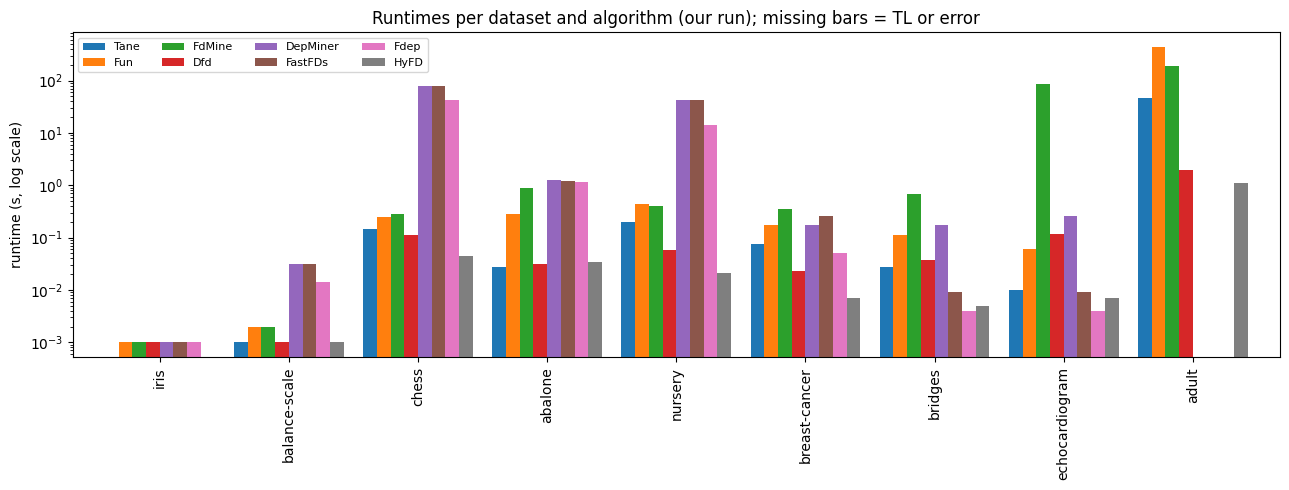

In [42]:
t = numeric(runtimes)
ax = t.plot(kind="bar", logy=True, figsize=(13, 5), width=0.85)
ax.set_ylabel("runtime (s, log scale)")
ax.set_title("Runtimes per dataset and algorithm (our run); missing bars = TL or error")
ax.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.savefig("table1_runtimes.png", dpi=200); plt.show()

## 6. Extra experiment: row scalability (style of Figure 6)

The paper's Figure 6 uses ncvoter and uniprot, which are not publicly available in that form. As a substitute we take the first *n* rows of Adult and time every algorithm. The expectation from the paper: HyFD stays fastest as the number of rows grows, and the record-comparison algorithms (Dep-Miner, FastFDs, Fdep) slow down fastest, because they compare record pairs (quadratic in rows).

In [43]:
scaling = {}
adult = DATASETS["adult"]
for n in SCALING_ROWS:
    path = os.path.join(DATA_DIR, f"adult_{n}.csv")
    adult.head(n).to_csv(path, header=False, index=False)
    scaling[n] = {}
    for algo in ALGORITHMS:
        # skip an algorithm once it has hit the time limit on fewer rows
        if any(scaling[m].get(algo) == "TL" for m in scaling if m < n):
            scaling[n][algo] = "TL"
            continue
        fds, t = run(algo, path, repeats=1)
        scaling[n][algo] = round(t, 3) if t is not None else fds
    print(n, scaling[n])
scaling = pd.DataFrame(scaling).T
scaling

1000 {'Tane': 0.924, 'Fun': 9.344, 'FdMine': 42.25, 'Dfd': 0.121, 'DepMiner': 2.158, 'FastFDs': 0.615, 'Fdep': 0.226, 'HyFD': 0.021}
2000 {'Tane': 1.582, 'Fun': 15.128, 'FdMine': 44.699, 'Dfd': 0.117, 'DepMiner': 9.081, 'FastFDs': 2.439, 'Fdep': 0.863, 'HyFD': 0.03}
4000 {'Tane': 4.192, 'Fun': 27.341, 'FdMine': 49.618, 'Dfd': 0.179, 'DepMiner': 15.099, 'FastFDs': 11.142, 'Fdep': 3.362, 'HyFD': 0.055}
8000 {'Tane': 7.383, 'Fun': 53.502, 'FdMine': 67.298, 'Dfd': 0.297, 'DepMiner': 46.821, 'FastFDs': 46.659, 'Fdep': 14.612, 'HyFD': 0.083}


KeyboardInterrupt: 

**Note:** the scaling run above was stopped manually at 16,000 rows because of limited time (hence the KeyboardInterrupt). The cell below keeps only the row sizes where all eight algorithms finished (1,000 to 8,000 rows).

In [44]:
scaling = {n: r for n, r in scaling.items() if len(r) == len(ALGORITHMS)}
scaling = pd.DataFrame(scaling).T
scaling

,Tane,Fun,FdMine,Dfd,DepMiner,FastFDs,Fdep,HyFD
1000,0.924,9.344,42.250,0.121,2.158,0.615,0.226,0.021
2000,1.582,15.128,44.699,0.117,9.081,2.439,0.863,0.030
4000,4.192,27.341,49.618,0.179,15.099,11.142,3.362,0.055
8000,7.383,53.502,67.298,0.297,46.821,46.659,14.612,0.083


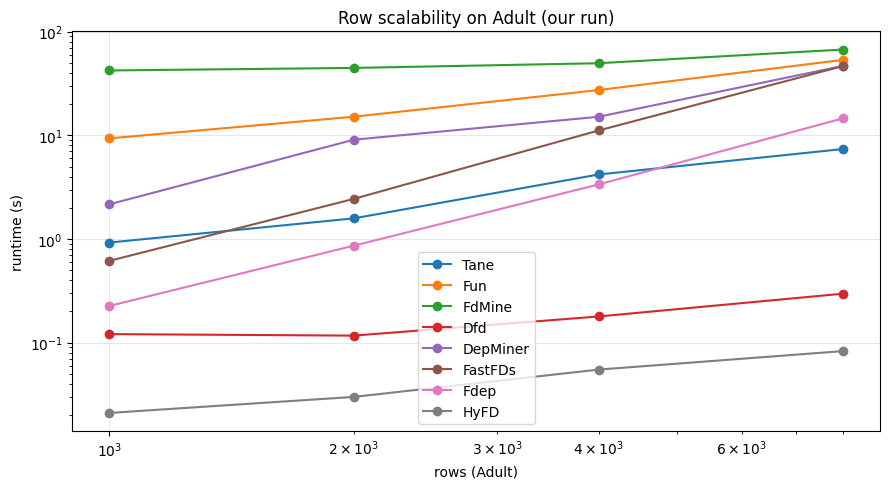

In [45]:
s = numeric(scaling)
ax = s.plot(marker="o", logx=True, logy=True, figsize=(9, 5))
ax.set_xlabel("rows (Adult)"); ax.set_ylabel("runtime (s)")
ax.set_title("Row scalability on Adult (our run)")
ax.grid(alpha=.3); plt.tight_layout(); plt.savefig("row_scalability.png", dpi=200); plt.show()

## 7. Parameters used

| Parameter | Value |
|---|---|
| Implementation | Desbordante 2.5.0 (Python library) for all 8 algorithms |
| HyFD efficiency threshold | 1% (paper default, fixed in the library) |
| Threads | 1 (single-threaded, as in Table 1 of the paper) |
| Time limit | 600 s per run (paper: 4 hours) |
| Memory limit | none set (paper: 100 GB) |
| Max. left-hand side size | none |
| Null semantics | null = null; `?` and empty values treated as ordinary values |
| Repeats | median of 3 runs (1 run if > 60 s) |
| Timing | discovery only, excluding reading the file |
| Datasets | 9 of 12 UCI datasets; letter, hepatitis and horse not run because of limited time |
| Stopped runs | Dep-Miner, FastFDs and Fdep on adult; row scaling stopped at 8,000 rows |
| Hardware / software | Google Colab, Linux x86_64, 2 CPU cores, Python 3.13.16, pandas 2.2.3, numpy 2.1.3 |

In [4]:
import desbordante
print("Python", sys.version.split()[0], "|", platform.platform(), "|", platform.processor())
print("CPU cores:", os.cpu_count())
for pkg in ["desbordante", "pandas", "numpy"]:
    try:
        from importlib.metadata import version
        print(pkg, version(pkg))
    except Exception:
        pass

Python 3.13.16 | Linux-6.6.122+-x86_64-with-glibc2.39 | x86_64
CPU cores: 2
desbordante 2.5.0
pandas 2.2.3
numpy 2.1.3


## Task 2: where each requirement is answered

| Requirement | Where in this notebook |
|---|---|
| Implementation | Title cell (Implementation) and section 4: Desbordante, a Python library that contains HyFD and the seven other algorithms |
| 1. Main experiment reproduced | Table 1 of the paper (Section 10.4): sections 2–5. Extra: row scalability (Figure 6 style) in section 6 |
| 2. Comparison with the paper | Sections 5.1–5.3 (tables and chart) and sections 1–3 of the report below |
| 3. Parameters and values | Parameters cell (top) and section 7 |
| 4. Explanation of differences | Section 4 of the report below |

# Reproduction of the HyFD Paper

## 1. Comparison of the Number of Functional Dependencies

The number of functional dependencies (FDs) discovered by HyFD was compared with the results reported in the original paper. The results matched for several datasets, including iris (4 FDs), balance-scale (1 FD), chess (1 FD), abalone (137 FDs), nursery (1 FD), breast-cancer (46 FDs), and bridges (142 FDs).

However, some differences were observed. For example, HyFD discovered 583 FDs for the echocardiogram dataset, compared with 527 in the original paper. For the Adult dataset, HyFD discovered 85 FDs, while the paper reported 78. One possible reason for the difference in the Adult results is that the dataset used in this experiment contains 15 columns, whereas the paper reports 14 columns. Differences in dataset versions, preprocessing, software implementations, or experimental settings may also affect the results.

FdMine found more functional dependencies because it also reports non-minimal functional dependencies, whereas the comparison focuses on minimal functional dependencies.

## 2. Runtime Comparison

The runtime results show that HyFD was generally one of the fastest algorithms tested, although it was not always the fastest on every dataset.

For example, on the chess dataset, HyFD completed in approximately 0.044 seconds, compared with 78.579 seconds for Dep-Miner and 80.459 seconds for FastFDs. This shows a substantial runtime advantage for HyFD on this dataset.

However, the fastest algorithm depended on the dataset. TANE was faster than HyFD on abalone, while Fdep was faster than HyFD on bridges and echocardiogram. Therefore, the results support the conclusion that HyFD performs very well overall, but they do not show that it is always the fastest algorithm.

The differences in runtime may be influenced by the dataset structure, the number of rows and columns, the number of dependencies to discover, and the software and hardware used for the experiment.

## 3. Effect of Increasing the Number of Rows

The Adult dataset was used to investigate how runtime changes when the number of rows increases.

| Number of rows | HyFD (seconds) | Dep-Miner (seconds) | FastFDs (seconds) |
|---:|---:|---:|---:|
| 1,000 | 0.021 | 2.158 | 0.615 |
| 2,000 | 0.030 | 9.081 | 2.439 |
| 4,000 | 0.055 | 15.099 | 11.142 |
| 8,000 | 0.083 | 46.821 | 46.659 |

The results show that runtime increased as the number of rows increased. However, the increase was much smaller for HyFD than for Dep-Miner and FastFDs in these experiments.

For example, HyFD increased from 0.021 seconds for 1,000 rows to 0.083 seconds for 8,000 rows. In contrast, Dep-Miner increased from 2.158 seconds to 46.821 seconds, while FastFDs increased from 0.615 seconds to 46.659 seconds.

These results suggest that HyFD handled the increase in the number of rows more efficiently for this dataset and experimental setup. However, the results should not be interpreted as proof that HyFD will always outperform the other algorithms on every dataset.

## 4. Differences Between the Reproduction and the Original Paper

The reproduction results were not identical to those reported in the original paper. Some datasets produced the same number of FDs, while others produced different counts. Runtime results also differed.

One possible explanation is that the reproduction used a different software environment. The experiment used Desbordante version 2.5.0 and Python 3.13.16, with a limit of 600 seconds for each algorithm. The original paper used the Metanome framework and Java-based implementations, with a four-hour time limit and a memory limit of 100 GB for its dataset comparison experiment.

These differences in software, implementation, hardware, dataset versions, preprocessing, and execution limits can affect the results. The time limit is particularly important because an algorithm stopped before finishing may not produce a complete result.

My experiment used the `null = null` setting, which is the same setting used in the original paper.

The results indicate that all algorithms except FdMine found the same functional dependencies on every dataset, suggesting that the implementations were consistent with one another. The letter, hepatitis, and horse datasets were not run, and some of the slower experiments on the Adult dataset were stopped because of limited time. The experiments were conducted in Google Colab using a machine with two CPU cores, which is different from the server used in the original paper. The original experiments used Java-based implementations, so differences in the software environment and execution overhead may also affect runtime comparisons.

The iris speed-up calculation also requires care. If HyFD and the fastest competing algorithm both have a recorded runtime of 0.0 seconds, the speed-up cannot be calculated by dividing one runtime by the other, because this results in division by zero. The result should therefore be treated as undefined rather than as a meaningful speed-up value.

Overall, the reproduction supports the general finding that HyFD can discover functional dependencies efficiently. Nevertheless, exact agreement with the paper cannot be expected unless the datasets, implementations, settings, and experimental environment are consistent.

## 5. Conclusion

The experiments show that HyFD generally performed efficiently and scaled better than Dep-Miner and FastFDs in the tested row-scaling experiment. On the chess dataset, it was substantially faster than the two algorithms for which the runtime results were compared. However, HyFD was not the fastest on every dataset: TANE was faster on abalone, and Fdep was faster on bridges and echocardiogram.

The number of discovered FDs matched the original paper on several datasets but differed on others, including echocardiogram and Adult. These differences may be related to dataset versions, preprocessing, implementation details, or experimental settings.

In conclusion, the reproduction broadly supports the paper's findings about HyFD's efficiency, but the results also demonstrate that performance depends on the dataset and experimental setup. The reproduction should therefore be viewed as supporting the paper's main conclusions rather than as an exact replication of every reported result.